# Лабораторна робота №2 "Baseline Classification Pipeline"
**Мета.** Відтворити базовий життєвий цикл машинного навчання для задачі класифікації: підготувати дані, розділити їх на навчальну та валідаційну вибірки, навчити модель, оцінити її якість та сформувати прогноз для тестових даних.

## Хід роботи

### Завантаження даних
Імпортуємо необхідні бібліотеки:

In [1]:
from getpass import getpass
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Перевіряємо, чи потрібні файли вже є в теці `data/`. Якщо хоча б одного немає і вхід у Kaggle ще не виконано, запитуємо API-токен Kaggle. Перед завантаженням потрібно також прийняти правила змагання на сторінці Kaggle.

In [2]:
DATA_DIR = Path("data")
COMPETITION = "home-credit-default-risk"
FILES = [
    "application_train.csv",
    "application_test.csv",
    "sample_submission.csv",
    "HomeCredit_columns_description.csv",
]

missing = [name for name in FILES if not (DATA_DIR / name).exists()]
if missing:
    print("Відсутні файли:", ", ".join(missing))
    try:
        kagglehub.whoami(verbose=False)
    except Exception:
        kagglehub.auth.set_kaggle_api_token(getpass("Перейдіть за посиланням: https://www.kaggle.com/settings/api, та введіть API-токен Kaggle: "))
    for name in missing:
        kagglehub.competition_download(COMPETITION, path=name, output_dir=str(DATA_DIR))

print("Файли даних:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Файли даних: ['HomeCredit_columns_description.csv', 'application_test.csv', 'application_train.csv', 'sample_submission.csv']


Завантажуємо навчальну та тестову вибірки й виводимо їхню форму:

In [3]:
train = pd.read_csv(DATA_DIR / "application_train.csv")
test = pd.read_csv(DATA_DIR / "application_test.csv")

print(f"Навчальна вибірка: {train.shape}")
print(f"Тестова вибірка: {test.shape}")

Навчальна вибірка: (307511, 122)
Тестова вибірка: (48744, 121)


Перші рядки навчальної вибірки:

In [4]:
train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


### Відокремлення цільової змінної від ознак
Цільова змінна `TARGET` показує, чи мав клієнт труднощі з поверненням кредиту (1) чи ні (0). Колонка `SK_ID_CURR` – це лише ідентифікатор заявки, тому до ознак її не включаємо, але ідентифікатори тестової вибірки зберігаємо для файлу з прогнозами:

In [5]:
y = train["TARGET"]
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
X_test = test.drop(columns=["SK_ID_CURR"])
test_ids = test["SK_ID_CURR"]

print(f"Ознаки X: {X.shape}, цільова змінна y: {y.shape}")
print(f"Ознаки тестової вибірки X_test: {X_test.shape}")
print("Набори ознак збігаються:", list(X.columns) == list(X_test.columns))

Ознаки X: (307511, 120), цільова змінна y: (307511,)
Ознаки тестової вибірки X_test: (48744, 120)
Набори ознак збігаються: True


Переглянемо розподіл класів цільової змінної:

In [6]:
print(y.value_counts())

TARGET
0    282686
1     24825
Name: count, dtype: int64


### Неможливі значення
Частина значень є заповнена, але фізично неможлива. Визначимо такі значення загальними правилами:
- ознаки `DAYS_*` – це дні відносно моменту подання заявки в минуле, тому мають бути $\le{0}$;
- у категоріальних ознаках `XNA` (*not available*) фактично є пропусками.

Такі значення замінюємо на пропуски в обох вибірках. Правило не залежить від статистик вибірки, тому витоку інформації з валідаційних даних немає:

In [7]:
def replace_placeholders(df):
    df = df.copy()
    days = [c for c in df.columns if c.startswith("DAYS_")]
    df[days] = df[days].mask(df[days] > 0)
    categorical = df.select_dtypes(exclude="number").columns
    df[categorical] = df[categorical].mask(df[categorical].eq("XNA"))
    return df

X_clean = replace_placeholders(X)
replaced = X_clean.isna().sum() - X.isna().sum()
print("Замінено на пропуски:")
print(replaced[replaced > 0])

X, X_test = X_clean, replace_placeholders(X_test)

Замінено на пропуски:
CODE_GENDER              4
DAYS_EMPLOYED        55374
ORGANIZATION_TYPE    55374
dtype: int64


### Відбір ознак
Спершу перевіряємо, чи немає повторених заявок:

In [8]:
print("Повторених рядків:", X.duplicated().sum())

Повторених рядків: 0


Ознаки, у яких пропущено більше половини значень, видаляємо. У таких колонках пропусків більше, ніж заповнених значень, тож після заповнення дані в них частіше були б вгадані, ніж надані клієнтом. Виключені ознаки та частка пропусків у них:

In [9]:
MAX_MISSING = 0.50

missing = X.isna().mean()
excluded = missing[missing > MAX_MISSING].sort_values(ascending=False)
selected = [c for c in X.columns if c not in excluded.index]

print(f"Виключено ознак: {len(excluded)}, залишилось: {len(selected)}")
with pd.option_context("display.max_rows", 100):
    display(excluded.mul(100).round(1).rename("пропуски, %"))

Виключено ознак: 41, залишилось: 79


COMMONAREA_AVG              69.9
COMMONAREA_MEDI             69.9
COMMONAREA_MODE             69.9
NONLIVINGAPARTMENTS_AVG     69.4
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_MEDI    69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MODE       68.4
LIVINGAPARTMENTS_MEDI       68.4
FLOORSMIN_MODE              67.8
FLOORSMIN_MEDI              67.8
FLOORSMIN_AVG               67.8
YEARS_BUILD_MODE            66.5
YEARS_BUILD_MEDI            66.5
YEARS_BUILD_AVG             66.5
OWN_CAR_AGE                 66.0
LANDAREA_MODE               59.4
LANDAREA_MEDI               59.4
LANDAREA_AVG                59.4
BASEMENTAREA_MODE           58.5
BASEMENTAREA_AVG            58.5
BASEMENTAREA_MEDI           58.5
EXT_SOURCE_1                56.4
NONLIVINGAREA_MEDI          55.2
NONLIVINGAREA_AVG           55.2
NONLIVINGAREA_MODE          55.2
ELEVATORS_AVG               53.3
ELEVATORS_MODE              53.3
ELEVATORS_MEDI              53.3
WALLSMATER

### Розділення на навчальну та валідаційну вибірки
Значення для заповнення пропусків (медіани) і категорії для кодування мають обчислюватися лише на навчальних даних, інакше інформація з валідаційної вибірки потрапить у навчання. Тому спочатку розділяємо дані: 80 % на навчання, 20 % на валідацію. Через дисбаланс класів розділяємо зі стратифікацією за `TARGET`, щоб частка класу 1 в обох частинах була однакова:

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X[selected], y, test_size=0.2, stratify=y, random_state=42
)
X_test = X_test[selected]

print(f"Навчальна: {X_train.shape}, частка класу 1: {y_train.mean():.2%}")
print(f"Валідаційна: {X_val.shape}, частка класу 1: {y_val.mean():.2%}")
print(f"Тестова: {X_test.shape}")

Навчальна: (246008, 79), частка класу 1: 8.07%
Валідаційна: (61503, 79), частка класу 1: 8.07%
Тестова: (48744, 79)


### Заповнення пропусків і кодування категоріальних ознак
Для кожного типу ознак застосовуємо одне правило:
- числові ознаки – заповнюємо медіаною.
- категоріальні ознаки – пропуск стає окремою категорією `Unknown`, бо відсутність значення сама може нести інформацію, після чого кодуємо категорії цілими числами (ordinal encoding). Для дерева рішень такого кодування достатньо, і, на відміну від one-hot, воно не збільшує кількість ознак. Категорія, якої не було в навчальних даних, отримує код −1.

Обробку навчаємо на навчальній вибірці та застосовуємо до валідаційної й тестової:

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder

categorical_selected = X_train.select_dtypes(exclude="number").columns
numeric_selected = X_train.columns.difference(categorical_selected)

preprocessor = ColumnTransformer(
    [
        ("numeric", SimpleImputer(strategy="median"), numeric_selected),
        ("categorical", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="Unknown"),
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        ), categorical_selected),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

for name, data in [("навчальна", X_train_prepared), ("валідаційна", X_val_prepared), ("тестова", X_test_prepared)]:
    print(f"{name}: {data.shape}, пропусків: {data.isna().sum().sum()}, нечислових ознак: {data.select_dtypes(exclude='number').shape[1]}")

навчальна: (246008, 79), пропусків: 0, нечислових ознак: 0
валідаційна: (61503, 79), пропусків: 0, нечислових ознак: 0
тестова: (48744, 79), пропусків: 0, нечислових ознак: 0


Перевіримо, як закодовано категоріальні ознаки, на прикладі `OCCUPATION_TYPE`, де пропущено 31 % значень. Пропуски стали окремою категорією `Unknown` з власним кодом:

In [12]:
encoder = preprocessor.named_transformers_["categorical"][-1]
occupation_categories = encoder.categories_[list(categorical_selected).index("OCCUPATION_TYPE")]
pd.Series(range(len(occupation_categories)), index=occupation_categories, name="код")

Accountants               0
Cleaning staff            1
Cooking staff             2
Core staff                3
Drivers                   4
HR staff                  5
High skill tech staff     6
IT staff                  7
Laborers                  8
Low-skill Laborers        9
Managers                 10
Medicine staff           11
Private service staff    12
Realty agents            13
Sales staff              14
Secretaries              15
Security staff           16
Unknown                  17
Waiters/barmen staff     18
Name: код, dtype: int64

### Навчання моделі
Навчаємо дерево рішень із параметрами за замовчуванням. Задаємо лише `random_state`, щоб результат був відтворюваним: за рівних варіантів розбиття дерево обирає ознаку випадково.

In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train_prepared, y_train)

print(f"Глибина дерева: {model.get_depth()}, кількість листків: {model.get_n_leaves()}")

Глибина дерева: 47, кількість листків: 20389


### Оцінка якості за ROC-AUC
ROC-AUC показує, наскільки добре модель відрізняє клієнтів, які мали труднощі з поверненням кредиту, від решти. Це ймовірність того, що випадково обраний клієнт класу 1 отримає від моделі вищу оцінку ризику, ніж випадково обраний клієнт класу 0: 1 означає ідеальне розрізнення, 0.5 – випадкове вгадування. Тому для обчислення беремо не готову відповідь моделі (0 чи 1), а ймовірність класу 1, яку модель дає кожному клієнту.

Щоб перевірити, чи модель не перенавчилась, рахуємо метрику і на навчальній, і на валідаційній вибірці:

In [14]:
from sklearn.metrics import roc_auc_score

train_proba = model.predict_proba(X_train_prepared)[:, 1]
val_proba = model.predict_proba(X_val_prepared)[:, 1]

print(f"ROC-AUC на навчальній вибірці: {roc_auc_score(y_train, train_proba):.4f}")
print(f"ROC-AUC на валідаційній вибірці: {roc_auc_score(y_val, val_proba):.4f}")

ROC-AUC на навчальній вибірці: 1.0000
ROC-AUC на валідаційній вибірці: 0.5385


На навчальній вибірці ROC-AUC дорівнює 1.0, тобто модель безпомилково відтворює навчальні дані. На валідаційній вибірці ROC-AUC лише 0.539, що ненабагато краще за випадкове вгадування (0.5). Це ознака сильного перенавчання: без обмежень дерево виросло до глибини 47 і має понад 20 тисяч листків, тож воно запам'ятало навчальні приклади замість того, щоб знайти загальні закономірності. Для базової моделі з параметрами за замовчуванням такий результат очікуваний, а підбір параметрів у цій роботі не передбачений.

### Матриця помилок
Матриця помилок показує, скільки клієнтів кожного класу модель віднесла до правильного й неправильного класу. Тут потрібні вже готові відповіді моделі (0 чи 1), тому використовуємо `predict`, який відносить клієнта до класу 1, якщо ймовірність цього класу перевищує 0.5:

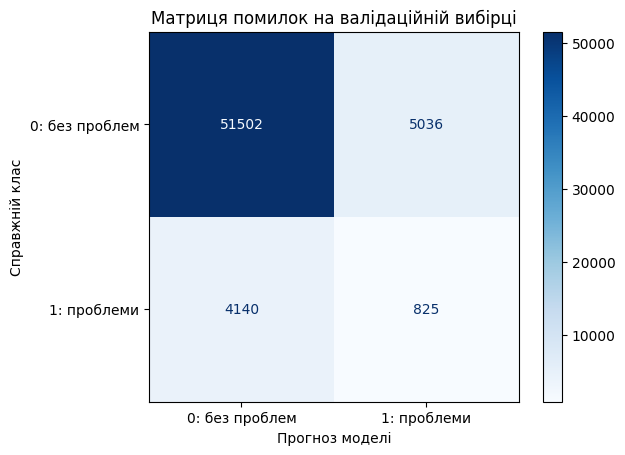

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

val_pred = model.predict(X_val_prepared)
tn, fp, fn, tp = confusion_matrix(y_val, val_pred).ravel()

ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, display_labels=["0: без проблем", "1: проблеми"], values_format="d", cmap="Blues"
)
plt.xlabel("Прогноз моделі")
plt.ylabel("Справжній клас")
plt.title("Матриця помилок на валідаційній вибірці")
plt.show()

### Аналіз помилок
Розглянемо обидва типи помилок окремо:
- **false positives (FP)** – клієнт повернув кредит без проблем, але модель передбачила проблеми; для банку це втрачений надійний клієнт;
- **false negatives (FN)** – клієнт мав труднощі з поверненням, але модель їх не передбачила; для банку це кредит, який може бути не повернений.

Порівняємо також точність моделі з найпростішим правилом «завжди прогнозувати клас 0»:

In [16]:
print(f"False positives (FP): {fp}, false negatives (FN): {fn}, true positives (TP): {tp}, true negatives (TN): {tn}")
print(f"Частка знайдених проблемних клієнтів (recall): {tp / (tp + fn):.1%}")
print(f"Частка справді проблемних серед позначених моделлю (precision): {tp / (tp + fp):.1%}")
print(f"Частка надійних клієнтів, помилково позначених проблемними: {fp / (fp + tn):.1%}")
print()
print(f"Точність (accuracy) моделі: {(tp + tn) / len(y_val):.1%}")
print(f"Точність правила «завжди 0»: {(y_val == 0).mean():.1%}")

False positives (FP): 5036, false negatives (FN): 4140, true positives (TP): 825, true negatives (TN): 51502
Частка знайдених проблемних клієнтів (recall): 16.6%
Частка справді проблемних серед позначених моделлю (precision): 14.1%
Частка надійних клієнтів, помилково позначених проблемними: 8.9%

Точність (accuracy) моделі: 85.1%
Точність правила «завжди 0»: 91.9%


**Висновки з аналізу помилок:**
- Із 4965 проблемних клієнтів валідаційної вибірки модель знайшла лише 825 (16.6 %), а 4140 пропустила.
- Із 5861 клієнта, якого модель позначила проблемним, справді проблемні лише 14.1 %; решта 5036 – надійні клієнти, помилково позначені як ризиковані (8.9 % усіх надійних).
- False positives (5036) більше, ніж true positives (825), тому модель погано придатна для відбору ризикових заявок.
- Точність моделі (85.1 %) нижча, ніж у правила «завжди 0» (91.9 %). Через дисбаланс класів точність тут оманлива, тому якість оцінюємо за ROC-AUC.
- Причина – перенавчання: дерево запам'ятало навчальні приклади, кожен листок містить приклади лише одного класу, і модель видає лише ймовірності 0 або 1 замість поступової оцінки ризику.

### Прогноз для тестової вибірки
Для прогнозу використовуємо ту саму модель, яку оцінили на валідаційній вибірці. Для кожної заявки тестової вибірки записуємо ймовірність класу 1 у форматі файлу `sample_submission.csv` і перевіряємо, що колонки та ідентифікатори заявок збігаються з ним:

In [17]:
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
submission = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "TARGET": model.predict_proba(X_test_prepared)[:, 1],
})

print("Колонки збігаються:", list(submission.columns) == list(sample_submission.columns))
print("Ідентифікатори збігаються:", set(submission["SK_ID_CURR"]) == set(sample_submission["SK_ID_CURR"]))
print("Кількість заявок:", len(submission))

submission.to_csv("submission.csv", index=False)
submission.head()

Колонки збігаються: True
Ідентифікатори збігаються: True
Кількість заявок: 48744


,SK_ID_CURR,TARGET
0,100001,0.0
1,100005,0.0
2,100013,0.0
3,100028,0.0
4,100038,0.0


### Результат на Kaggle
Файл `submission.csv` завантажено на сторінку змагання (Leaderboard → Late Submission). Отримана оцінка:

![Результат на Kaggle](kaggle_score.png)

На Kaggle модель отримала ROC-AUC 0.533 на приватній частині тестових даних і 0.522 на публічній. Це близько до оцінки на валідаційній вибірці (0.539): валідація правильно передбачила якість моделі на нових даних, а сама модель через перенавчання лише трохи краща за випадкове вгадування (0.5).

## Висновки
- У навчальних даних виявлено сильний дисбаланс класів: клієнтів із труднощами в поверненні кредиту лише 8.07 %.
- Із 120 ознак видалено 41, у яких пропущено більше половини значень. У решті 79 ознак заглушки замінено на пропуски, пропуски заповнено медіаною (числові) або окремою категорією `Unknown` (категоріальні), а категоріальні ознаки закодовано цілими числами.
- Дерево рішень із параметрами за замовчуванням має ROC-AUC 1.0 на навчальній вибірці та 0.539 на валідаційній. На Kaggle модель отримала 0.533 (private) та 0.522 (public), що узгоджується з оцінкою на валідації.
- Модель сильно перенавчена: дерево глибиною 47 запам'ятало навчальні приклади і видає лише ймовірності 0 або 1.
- Модель знаходить лише 16.6 % проблемних клієнтів, а false positives (5036) переважають true positives (825).
- Accuracy моделі (85.1 %) нижча, ніж у прогнозу «завжди 0» (91.9 %), тому при незбалансованих класах якість доцільно оцінювати за ROC-AUC.